# Métodos iterativos

## Método de Jacobi
Es un algoritmo iterativo diseñado para calcular todos los eigenvalores (eigenvalores) y eigenvectores (eigenvectores) de una matriz simétrica real 

\begin{equation}
 A \in \mathbb{R}^{n \times n}, \quad A = A^T.
\end{equation}

Consiste en aplicar una sucesión de transformaciones ortogonales que van anulando los elementos fuera de la diagonal principal hasta que la matriz converge a una forma diagonal

\begin{equation}
 D = V^T A V,
\end{equation}
donde los elementos de la diagonal de $D$ son los eigenvalores de $A$ y las columnas de la matriz acumulada $V = J_1 J_2 \cdots J_k$ son los eigenvectores correspondientes.

En cada iteración, se busca eliminar el elemento fuera de la diagonal con mayor magnitud absoluta, ubicado en la posición $(p, q)$ con $p \neq q$. Para lograrlo, se construye una matriz de rotación de Jacobi $J(p, q, \theta)$, que es idéntica a la matriz identidad excepto en cuatro entradas

\begin{equation}
 J_{pp} = \cos(\theta), \quad J_{qq} = \cos(\theta), \quad J_{pq} = \sin(\theta), \quad J_{qp} = -\sin(\theta).
\end{equation}

Al aplicar la transformación de semejanza $A' = J^T A J$, solo se modifican las filas y columnas $p$ y $q$. El ángulo $\theta$ se elige específicamente para forzar que el nuevo elemento $a'_{pq} = a'_{qp} = 0$.

### Cálculo de $\cos(\theta)$ y $\sin(\theta)$ 
Para evitar errores numéricos y el costo computacional de calcular $\arctan$, $\sin$ y $\cos$, se utilizan relaciones algebraicas directas:

1. Se define el parámetro $\tau$

\begin{equation}
 \tau = \frac{a_{qq} - a_{pp}}{2 a_{pq}}.
\end{equation}

2. Se calcula $t = \tan\theta$ eligiendo la raíz de menor magnitud de $t^2 + 2\tau t - 1 = 0$ (esto garantiza $\vert{}\theta\vert{} \le \frac{\pi}{4}$ y máxima estabilidad)

\begin{equation}
 t = \frac{\text{sgn}(\tau)}{\vert{}\tau\vert{} + \sqrt{1 + \tau^2}}.
\end{equation}

(Si $\tau = 0$, se toma $t = 1$).

3. Se obtienen $c = \cos(\theta)$ y $s = \sin(\theta)$

\begin{equation}
 c = \frac{1}{\sqrt{1 + t^2}}, \qquad s = c \cdot t.
\end{equation}

### Algoritmo paso a paso

1. **Inicialización.** Sea $A^{(0)} = A$ y $V^{(0)} = I_n$ (matriz identidad de tamaño $n \times n$).
2. **Búsqueda del pivote.** Encontrar los índices $(p, q)$ con $p < q$ tales que $\vert{}a_{pq}\vert{}$ sea el máximo entre todos los elementos fuera de la diagonal.
3. **Criterio de parada.** Si $\vert{}a_{pq}\vert{} < \epsilon$ (tolerancia deseada, por ejemplo $10^{-10}$), detener el ciclo.
4. **Rotación.** Calcular $c$ y $s$, actualizar la matriz $A^{(k+1)} = J^T A^{(k)} J$ y acumular los eigenvectores en $V^{(k+1)} = V^{(k)} J$.
5. Repetir desde el paso 2.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

# Suprimir advertencias menores de integración durante los bucles de optimización
import warnings
warnings.filterwarnings("ignore")

# Configurar el estilo de graficación para una mejor visualización
plt.style.use('ggplot')

In [2]:
def metodo_Jacobi(A, tol=1e-10, max_iter=1000):
    """
    Calcula los eigenvalores y eigenvectores de una
    matriz simétrica real mediante el método de Jacobi,
    registrando el historial de convergencia.
    """
    A = np.array(A, dtype=float)
    n = A.shape[0]
    
    if A.shape[0] != A.shape[1]:
        raise ValueError("La matriz debe ser cuadrada.")
    if not np.allclose(A, A.T):
        raise ValueError("El método de Jacobi requiere una matriz simétrica.")
    
    V = np.eye(n)
    error_history = []
    
    for _ in range(max_iter):
        # 1. Encontrar el mayor elemento fuera de la diagonal
        off_diag = np.abs(A - np.diag(np.diag(A)))
        p, q = np.unravel_index(np.argmax(off_diag), A.shape)
        max_error = off_diag[p, q]
        
        # Guardar el error de la iteración actual
        error_history.append(max_error)
        
        # 2. Criterio de parada
        if max_error < tol:
            break
            
        # 3. Calcular c = cos(theta) y s = sin(theta)
        if A[p, q] != 0:
            tau = (A[q, q] - A[p, p]) / (2.0 * A[p, q])
            if tau >= 0:
                t = 1.0 / (tau + np.sqrt(1.0 + tau**2))
            else:
                t = -1.0 / (-tau + np.sqrt(1.0 + tau**2))
                
            c = 1.0 / np.sqrt(1.0 + t**2)
            s = c * t
        else:
            c, s = 1.0, 0.0
            
        # 4. Actualizar matriz A
        app, aqq, apq = A[p, p], A[q, q], A[p, q]
        A[p, p] = c**2 * app - 2.0 * s * c * apq + s**2 * aqq
        A[q, q] = s**2 * app + 2.0 * s * c * apq + c**2 * aqq
        A[p, q] = 0.0
        A[q, p] = 0.0
        
        for i in range(n):
            if i != p and i != q:
                aip, aiq = A[i, p], A[i, q]
                A[i, p] = c * aip - s * aiq
                A[p, i] = A[i, p]
                A[i, q] = s * aip + c * aiq
                A[q, i] = A[i, q]
                
        # 5. Acumula los eigenvectores
        for i in range(n):
            vip, viq = V[i, p], V[i, q]
            V[i, p] = c * vip - s * viq
            V[i, q] = s * vip + c * viq
            
    # Extraer los eigenvalores
    eigenvalues = np.diag(A)
    idx_orden = np.argsort(eigenvalues)[::-1]
    
    eigenvalues = eigenvalues[idx_orden]
    V = V[:, idx_orden]
    
    return eigenvalues, V, error_history

Eigenvalores (Jacobi):
[29.00816702 11.81640893  2.71750235  1.07287503 -1.37028957 -7.24466376]

Eigenvectores (columnas):
[[ 0.33666304  0.61022947 -0.19543763 -0.66062462  0.06809406  0.18713746]
 [ 0.41627298 -0.30862623  0.0632463  -0.05439457  0.83366027 -0.17180902]
 [ 0.38241336  0.28038526  0.83434226  0.22927985 -0.11099208  0.11886394]
 [ 0.44733301 -0.18724229 -0.3529441   0.35132921 -0.09615705  0.7124504 ]
 [ 0.34899762  0.41576194 -0.3699778   0.5071309  -0.07317887 -0.55310234]
 [ 0.49520568 -0.4958188   0.01496387 -0.35697777 -0.52292751 -0.3283669 ]]

Eigenvalores (NumPy):
[29.00816702 11.81640893 -7.24466376  2.71750235  1.07287503 -1.37028957]

Eigenvectores (columnas):
[[ 0.33666304  0.61022947 -0.18713746  0.19543763  0.66062462 -0.06809406]
 [ 0.41627298 -0.30862623  0.17180902 -0.0632463   0.05439457 -0.83366027]
 [ 0.38241336  0.28038526 -0.11886394 -0.83434226 -0.22927985  0.11099208]
 [ 0.44733301 -0.18724229 -0.7124504   0.3529441  -0.35132921  0.09615705]
 

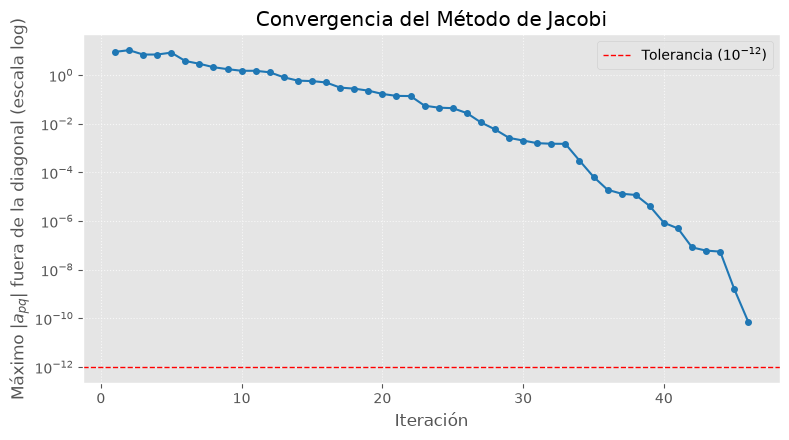

In [3]:
A = np.array([[8.0, 2.0, 5.0, 2.0, 7.0, 2.0],
              [2.0, 5.0, 4.0, 7.0, 2.0, 8.0],
              [5.0, 4.0, 7.0, 3.0, 5.0, 4.0],
              [2.0, 7.0, 3.0, 3.0, 7.0, 9.0],
              [7.0, 2.0, 5.0, 7.0, 4.0, 1.0],
              [2.0, 8.0, 4.0, 9.0, 1.0, 9.0]])
    
eig_val, eig_vec, jacobi_hist = metodo_Jacobi(A)

print("Eigenvalores (Jacobi):")
print(eig_val)
print("\nEigenvectores (columnas):")
print(eig_vec)

eig_val_np, eig_vec_np = np.linalg.eig(A)

print("\nEigenvalores (NumPy):")
print(eig_val_np.real)
print("\nEigenvectores (columnas):")
print(eig_vec_np.real)

# Verificación: M @ V - V @ diag(valores)
residuo = np.max(np.abs(A @ eig_vec - eig_vec @ np.diag(eig_val)))
print(f"\nError máximo de verificación: {residuo:.2e}")

# Graficar la convergencia en escala logarítmica
plt.figure(figsize=(8, 4.5))
plt.semilogy(range(1, len(jacobi_hist) + 1), jacobi_hist, marker='o', markersize=4, linewidth=1.5, color='#1f77b4')
plt.axhline(1e-12, color='red', linestyle='--', linewidth=1, label='Tolerancia ($10^{-12}$)')
plt.title('Convergencia del Método de Jacobi')
plt.xlabel('Iteración')
plt.ylabel('Máximo $|a_{pq}|$ fuera de la diagonal (escala log)')
plt.grid(True, which="both", linestyle=":", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

## Método de Givens (o rotaciones de Givens)

Calcula los eigenvalores y eigenvectores de una matriz simétrica real $A \in \mathbb{R}^{n \times n}$ en dos etapas definidas, a diferencia de Jacobi que diagonaliza directamente:

1. **Tridiagonalización (directa, sin iteraciones).** Aplica exactamente $\frac{(n-1)(n-2)}{2}$ rotaciones planas de Givens para anular todos los elementos fuera de las tres diagonales principales ($\vert{}i - j\vert{} > 1$), transformando $A$ en una matriz simétrica tridiagonal $T = Q^T A Q$.
2. **Diagonalización iterativa.** Aplica iteraciones QR utilizando rotaciones de Givens sobre la matriz tridiagonal $T$ (con desplazamientos de Wilkinson para acelerar la convergencia) hasta que la subdiagonal converge a cero.

Esto reduce drásticamente el costo computacional respecto a Jacobi porque las rotaciones sobre matrices tridiagonales cuestan $\mathcal{O}(n)$ en lugar de $\mathcal{O}(n^2)$ por paso.

### Fundamento de una rotación de Givens
Para anular el elemento $x_j$ usando como pivote $x_i$ en un vector, se construye una rotación ortogonal $G(i, j, \theta)$ donde $c = \cos\theta$ y $s = \sin\theta$ se calculan sin funciones trigonométricas mediante

\begin{equation}
 r = \sqrt{x_i^2 + x_j^2}, \qquad c = \frac{x_i}{r}, \qquad s = \frac{-x_j}{r}.
\end{equation}

Al multiplicar por $G$, la coordenada $i$ se transforma en $r$ y la coordenada $j$ se convierte exactamente en $0$.

In [4]:
def rotacion_givens(a, b):
    """Calcula c = cos(theta) y s = sin(theta) para anular b."""
    if b == 0.0:
        return 1.0, 0.0
    if abs(b) > abs(a):
        tau = -a / b
        s = 1.0 / np.sqrt(1.0 + tau**2)
        c = s * tau
    else:
        tau = -b / a
        c = 1.0 / np.sqrt(1.0 + tau**2)
        s = c * tau
    return c, s


def tridiagonalizacion_givens(A):
    """
    Fase 1: Reduce una matriz simétrica A a forma tridiagonal T = Q^T A Q
    mediante rotaciones planas de Givens.
    """
    T = A.copy().astype(float)
    n = T.shape[0]
    Q = np.eye(n)
    
    for j in range(n - 2):
        for i in range(n - 1, j + 1, -1):
            if T[i, j] != 0.0:
                c, s = rotacion_givens(T[i - 1, j], T[i, j])
                
                # Aplicar rotación por la izquierda (filas i-1, i)
                G_sub = np.array([[c, -s], [s, c]])
                T[[i - 1, i], :] = G_sub @ T[[i - 1, i], :]
                
                # Aplicar rotación por la derecha (columnas i-1, i)
                T[:, [i - 1, i]] = T[:, [i - 1, i]] @ G_sub.T
                
                # Acumular vectores ortogonales: Q = Q * G^T
                Q[:, [i - 1, i]] = Q[:, [i - 1, i]] @ G_sub.T
                
    return T, Q

def metodo_Givens(A, tol=1e-12, max_iter=1000):
    """
    Calcula los eigenvalores y eigeneigenvectores de una
    matriz simétrica usando tridiagonalización de Givens + QR con Givens.
    """
    if A.shape[0] != A.shape[1]:
        raise ValueError("La matriz debe ser cuadrada.")
    if not np.allclose(A, A.T):
        raise ValueError("El método requiere una matriz simétrica.")
        
    n = A.shape[0]
    # Fase 1: Tridiagonalización
    T, Q = tridiagonalizacion_givens(A)
    error_history = []
    
    # Fase 2: Iteraciones QR con rotaciones de Givens y desplazamiento de Wilkinson
    for _ in range(max_iter):
        # El error es el máximo elemento en la subdiagonal
        subdiag = np.abs(np.diag(T, k=-1))
        max_error = np.max(subdiag) if len(subdiag) > 0 else 0.0
        error_history.append(max_error)
        
        if max_error < tol:
            break
            
        # Desplazamiento de Wilkinson usando el bloque inferior 2x2
        d = (T[n - 2, n - 2] - T[n - 1, n - 1]) / 2.0
        b2 = T[n - 1, n - 2]**2
        sign_d = 1.0 if d >= 0 else -1.0
        mu = T[n - 1, n - 1] - (sign_d * b2) / (abs(d) + np.sqrt(d**2 + b2))
        
        # T - mu * I
        T_shifted = T - mu * np.eye(n)
        
        # Factorización QR de T_shifted usando rotaciones de Givens
        rotations = []
        for i in range(n - 1):
            c, s = rotacion_givens(T_shifted[i, i], T_shifted[i + 1, i])
            G_sub = np.array([[c, -s], [s, c]])
            T_shifted[[i, i + 1], :] = G_sub @ T_shifted[[i, i + 1], :]
            rotations.append((i, c, s))
            
        # Formar T_next = R * Q_qr + mu * I y acumular eigenvectores
        for i, c, s in rotations:
            G_sub_T = np.array([[c, s], [-s, c]])
            T_shifted[:, [i, i + 1]] = T_shifted[:, [i, i + 1]] @ G_sub_T
            Q[:, [i, i + 1]] = Q[:, [i, i + 1]] @ G_sub_T
            
        T = T_shifted + mu * np.eye(n)
        
    # Extraer los eigenvalores
    eigenvalues = np.diag(T)
    idx_orden = np.argsort(eigenvalues)[::-1]
    
    eigenvalues = eigenvalues[idx_orden]
    Q = Q[:, idx_orden]
    
    return eigenvalues, Q, error_history

Eigenvalores (Método de Givens):
[29.00816702 11.81640893  2.71750235  1.07287503 -1.37028957 -7.24466376]

Eigenvectores (columnas):
[[ 0.33666304  0.61022947 -0.19543763 -0.66062462  0.06809406 -0.18713746]
 [ 0.41627298 -0.30862623  0.0632463  -0.05439457  0.83366027  0.17180902]
 [ 0.38241336  0.28038526  0.83434226  0.22927985 -0.11099208 -0.11886394]
 [ 0.44733301 -0.18724229 -0.3529441   0.35132921 -0.09615705 -0.7124504 ]
 [ 0.34899762  0.41576194 -0.3699778   0.5071309  -0.07317887  0.55310234]
 [ 0.49520568 -0.4958188   0.01496387 -0.35697777 -0.52292751  0.3283669 ]]

Error máximo de verificación: 7.56e-13


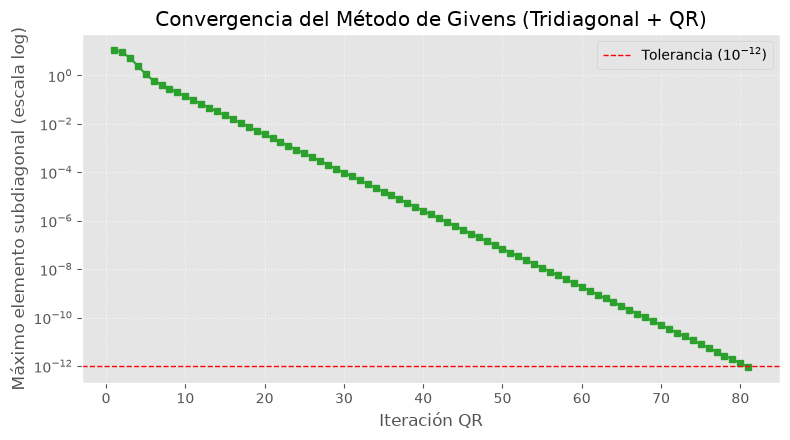

In [5]:
eig_val_g, eig_vec_g, givens_hist = metodo_Givens(A, tol=1e-12)
    
print("Eigenvalores (Método de Givens):")
print(eig_val_g)
print("\nEigenvectores (columnas):")
print(eig_vec_g)

# Verificación: M @ V - V @ diag(valores)
residuo_giv = np.max(np.abs(A @ eig_vec_g - eig_vec_g @ np.diag(eig_val_g)))
print(f"\nError máximo de verificación: {residuo_giv:.2e}")

# Graficar convergencia de la subdiagonal
plt.figure(figsize=(8, 4.5))
plt.semilogy(range(1, len(givens_hist) + 1), givens_hist, marker='s', markersize=4, linewidth=1.5, color='#2ca02c')
plt.axhline(1e-12, color='red', linestyle='--', linewidth=1, label='Tolerancia ($10^{-12}$)')
plt.title('Convergencia del Método de Givens (Tridiagonal + QR)')
plt.xlabel('Iteración QR')
plt.ylabel('Máximo elemento subdiagonal (escala log)')
plt.grid(True, which="both", linestyle=":", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

## Método de Householder

Mientras que el método de Givens anula elementos de uno en uno mediante rotaciones planas, Householder utiliza reflexiones especulares sobre hiperplanos para anular toda una columna debajo de la subdiagonal en un solo paso.

Una matriz de Householder $H$ tiene la forma:

\begin{equation}
 H = I - 2\frac{v v^T}{v^T v}.
\end{equation}

Geométricamente, $H$ refleja cualquier vector $x$ a través del hiperplano ortogonal al vector normal $v$. Es una matriz simétrica ($H^T = H$) y ortogonal ($H^T H = I$), por lo que $H^{-1} = H$.

### Construcción del vector reflector $v$

Tomamos el subvector debajo de la diagonal principal en la columna $k$

\begin{equation}
 x = \begin{bmatrix} a_{k+1, k} \\ a_{k+2, k} \\ \vdots \\ a_{n, k} \end{bmatrix}.
\end{equation}

Para evitar cancelación numérica (pérdida de cifras significativas), elegimos el signo opuesto al primer elemento de $x$

\begin{equation}
 \alpha = -\text{sgn}(x_1)\, \Vert{}x\Vert{}_2,
\end{equation}

\begin{equation}
 v = x - \alpha e_1 = \begin{bmatrix} x_1 - \alpha \\ x_2 \\ \vdots \\ x_{n-k} \end{bmatrix}.
\end{equation}

Aplicando la transformación de semejanza $A^{(k+1)} = H_k A^{(k)} H_k$, se anulan simultáneamente las entradas $a_{k+2, k}, \dots, a_{n, k}$ (y sus simétricas en la fila $k$). En $n - 2$ pasos, cualquier matriz simétrica se reduce a una matriz tridiagonal $T = Q^T A Q$.

### Algoritmo paso a paso
1. **Tridiagonalización de Householder ($O(\frac{4}{3}n^3)$).** Se aplican $n - 2$ reflexiones de Householder para transformar $A$ en la matriz tridiagonal $T$ y acumular la matriz ortogonal $Q = H_1 H_2 \cdots H_{n-2}$.
2. **Diagonalización QR con desplazamiento de Wilkinson.** Sobre la matriz tridiagonal $T$, se aplican iteraciones QR con rotaciones de Givens hasta que los elementos de la subdiagonal caen por debajo de la tolerancia $\epsilon$.

In [6]:
def tridiagonalizacion_householder(A):
    """
    Fase 1: Reduce una matriz simétrica A a forma tridiagonal T = Q^T A Q
    mediante n-2 reflexiones de Householder.
    """
    T = A.copy().astype(float)
    n = T.shape[0]
    Q = np.eye(n)
    
    for k in range(n - 2):
        # Subvector debajo de la diagonal en la columna k
        x = T[k + 1:, k]
        norm_x = np.linalg.norm(x)
        
        if norm_x == 0.0:
            continue
            
        # Elegir signo opuesto a x[0] para máxima estabilidad numérica
        sign = 1.0 if x[0] >= 0.0 else -1.0
        alpha = -sign * norm_x
        
        # Vector reflector v y normalización beta = 2 / (v^T v)
        v = x.copy()
        v[0] -= alpha
        v_norm_sq = np.dot(v, v)
        if v_norm_sq == 0.0:
            continue
        beta = 2.0 / v_norm_sq
        
        # Aplicar transformación simétrica T[k+1:, k+1:] = H * T_sub * H
        # de forma vectorial sin formar la matriz H completa
        T_sub = T[k + 1:, k + 1:]
        p = beta * (T_sub @ v)
        w = p - (0.5 * beta * np.dot(p, v)) * v
        
        T[k + 1:, k + 1:] = T_sub - np.outer(v, w) - np.outer(w, v)
        
        # Fijar los elementos fuera de la subdiagonal en la columna/fila k
        T[k + 1, k] = alpha
        T[k, k + 1] = alpha
        T[k + 2:, k] = 0.0
        T[k, k + 2:] = 0.0
        
        # Acumular los eigenvalores: Q[:, k+1:] = Q[:, k+1:] * H
        Q[:, k + 1:] -= beta * np.outer(Q[:, k + 1:] @ v, v)
        
    return T, Q


def rotacion_givens(a, b):
    """Rotación de Givens auxiliar para la fase QR tridiagonal."""
    if b == 0.0:
        return 1.0, 0.0
    if abs(b) > abs(a):
        tau = -a / b
        s = 1.0 / np.sqrt(1.0 + tau**2)
        c = s * tau
    else:
        tau = -b / a
        c = 1.0 / np.sqrt(1.0 + tau**2)
        s = c * tau
    return c, s


def metodo_Householder(A, tol=1e-12, max_iter=1000):
    """
    Calcula los eigenvalores y eigenvectores de una matriz simétrica
    usando tridiagonalización de Householder + QR tridiagonal.
    """
    if A.shape[0] != A.shape[1]:
        raise ValueError("La matriz debe ser cuadrada.")
    if not np.allclose(A, A.T):
        raise ValueError("El método requiere una matriz simétrica.")
        
    n = A.shape[0]
    # Fase 1: Tridiagonalización mediante reflexiones de Householder
    T, Q = tridiagonalizacion_householder(A)
    error_history = []
    
    # Fase 2: Diagonalización QR con desplazamiento de Wilkinson
    for _ in range(max_iter):
        subdiag = np.abs(np.diag(T, k=-1))
        max_error = np.max(subdiag) if len(subdiag) > 0 else 0.0
        error_history.append(max_error)
        
        if max_error < tol:
            break
            
        # Desplazamiento de Wilkinson
        d = (T[n - 2, n - 2] - T[n - 1, n - 1]) / 2.0
        b2 = T[n - 1, n - 2]**2
        sign_d = 1.0 if d >= 0 else -1.0
        mu = T[n - 1, n - 1] - (sign_d * b2) / (abs(d) + np.sqrt(d**2 + b2))
        
        T_shifted = T - mu * np.eye(n)
        
        # Factorización QR sobre la matriz tridiagonal
        rotations = []
        for i in range(n - 1):
            c, s = rotacion_givens(T_shifted[i, i], T_shifted[i + 1, i])
            G_sub = np.array([[c, -s], [s, c]])
            T_shifted[[i, i + 1], :] = G_sub @ T_shifted[[i, i + 1], :]
            rotations.append((i, c, s))
            
        for i, c, s in rotations:
            G_sub_T = np.array([[c, s], [-s, c]])
            T_shifted[:, [i, i + 1]] = T_shifted[:, [i, i + 1]] @ G_sub_T
            Q[:, [i, i + 1]] = Q[:, [i, i + 1]] @ G_sub_T
            
        T = T_shifted + mu * np.eye(n)
        
    # Extraer los eigenvalores
    eigenvalues = np.diag(T)
    idx_orden = np.argsort(eigenvalues)[::-1]
    
    eigenvalues = eigenvalues[idx_orden]
    Q = Q[:, idx_orden]
    
    return eigenvalues, Q, error_history

eigenvalores ordenados (Método de Householder):
[29.00816702 11.81640893  2.71750235  1.07287503 -1.37028957 -7.24466376]

eigenvectores correspondientes (columnas):
[[ 0.33666304  0.61022947 -0.19543763  0.66062462 -0.06809406 -0.18713746]
 [ 0.41627298 -0.30862623  0.0632463   0.05439457 -0.83366027  0.17180902]
 [ 0.38241336  0.28038526  0.83434226 -0.22927985  0.11099208 -0.11886394]
 [ 0.44733301 -0.18724229 -0.3529441  -0.35132921  0.09615705 -0.7124504 ]
 [ 0.34899762  0.41576194 -0.3699778  -0.5071309   0.07317887  0.55310234]
 [ 0.49520568 -0.4958188   0.01496387  0.35697777  0.52292751  0.3283669 ]]

Error máximo de verificación: 7.55e-13


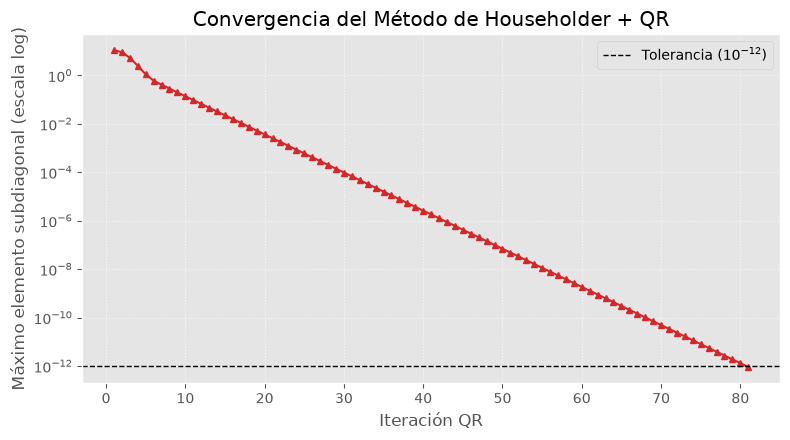

In [7]:
eig_val_h, eig_vec_h, givens_hist = metodo_Householder(A, tol=1e-12)

print("eigenvalores ordenados (Método de Householder):")
print(eig_val_h)
print("\neigenvectores correspondientes (columnas):")
print(eig_vec_h)

# Verificación de precisión: ||M*V - V*diag(valores)||
residuo = np.max(np.abs(A @ eig_vec_h - eig_vec_h @ np.diag(eig_val_h)))
print(f"\nError máximo de verificación: {residuo:.2e}")

# Graficar convergencia
plt.figure(figsize=(8, 4.5))
plt.semilogy(range(1, len(givens_hist) + 1), givens_hist, marker='^', markersize=5, linewidth=1.5, color='#d62728')
plt.axhline(1e-12, color='black', linestyle='--', linewidth=1, label='Tolerancia ($10^{-12}$)')
plt.title('Convergencia del Método de Householder + QR')
plt.xlabel('Iteración QR')
plt.ylabel('Máximo elemento subdiagonal (escala log)')
plt.grid(True, which="both", linestyle=":", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

## Método de Multiplicación Sucesiva por $y^{(k)}$ (Método de potencia)

Conocido en la literatura como el Método de la Potencia (Power Iteration), es el algoritmo iterativo más directo para hallar el eigenvalor dominante (el de mayor magnitud absoluta, $\vert{}\lambda_1\vert{} > \vert{}\lambda_2\vert{} \ge \dots \ge \vert{}\lambda_n\vert{}$) y su eigenvector asociado.

Parte de un vector inicial arbitrario $y^{(0)} \neq 0$, cualquier vector en $\mathbb{R}^n$ puede expresarse como combinación lineal de los eigenvectores $v_1, v_2, \dots, v_n$ de $A$

\begin{equation}
 y^{(0)} = c_1 v_1 + c_2 v_2 + \dots + c_n v_n.
\end{equation}

Al multiplicar sucesivamente por la matriz $A$, cada componente se escala por la potencia de su eigenvalor

\begin{equation}
 y^{(k)} = A^k y^{(0)} = \lambda_1^k \left[ c_1 v_1 + c_2 \left(\frac{\lambda_2}{\lambda_1}\right)^k v_2 + \dots + c_n \left(\frac{\lambda_n}{\lambda_1}\right)^k v_n \right].
\end{equation}

Como $\vert{}\lambda_1\vert{} > \vert{}\lambda_i\vert{}$ para todo $i \ge 2$, las razones $\left(\frac{\lambda_i}{\lambda_1}\right)^k \to 0$ cuando $k \to \infty$. En consecuencia, $y^{(k)}$ se alinea cada vez más con la dirección del eigenvector dominante $v_1$.

### Algoritmo paso a paso
Para evitar desbordamiento numérico al elevar $\lambda_1^k$, en cada paso se normaliza el vector:

1. **Multiplicación.** $z^{(k)} = A y^{(k-1)}$.
2. **Aproximación del eigenvalor (Cociente de Rayleigh)**

\begin{equation}
 \lambda_1^{(k)} = \frac{(y^{(k-1)})^T z^{(k)}}{(y^{(k-1)})^T y^{(k-1)}}.
\end{equation}

3. **Normalización.**

\begin{equation}
 y^{(k)} = \frac{z^{(k)}}{\Vert{}z^{(k)}\Vert{}_2}.
\end{equation}

Aplicando este mismo principio sobre $A^{-1}$ se obtiene el eigenvalor más pequeño (Potencia Inversa), y combinándolo con deflación o ortogonalización de Gram-Schmidt se obtienen múltiples pares propios.

In [8]:
def metodo_potencia(A, tol=1e-12, max_iter=1000):
    n = A.shape[0]
    y = np.ones(n) / np.sqrt(n)
    lam_old = 0.0

    for it in range(1, max_iter + 1):
        z = A @ y
        lam = float(np.dot(y, z))
        y = z / np.linalg.norm(z)
        if abs(lam - lam_old) < tol:
            break
        lam_old = lam

    return lam, y.reshape(-1, 1), it

## Método L-R (Rutishauser, 1958)
El método L-R (Left-Right) fue el primer algoritmo moderno basado en factorizaciones matriciales sucesivas para calcular todos los eigenvalores de una matriz general (incluso no simétrica).

### Algoritmo paso a paso

Consiste en factorizar la matriz en el producto de una matriz triangular inferior con unos en la diagonal ($L$) y una matriz triangular superior ($R$), para luego invertir el orden de multiplicación:

1. **Inicialización.** $A_0 = A$.
2. **En cada iteración $k = 0, 1, 2, \dots$:**
    1. Factorizar (descomposición LU sin pivoteo): $A_k = L_k R_k$.
    2. Recombinar en orden inverso: $A_{k+1} = R_k L_k$.
    
Dado que $L_k$ es invertible, podemos despejar $R_k = L_k^{-1} A_k$ y sustituirlo en el siguiente paso:

\begin{equation}
 A_{k+1} = R_k L_k = L_k^{-1} A_k L_k.
\end{equation}

Lo anterior demuestra que $A_{k+1}$ es semejante a $A_k$, por lo que tiene exactamente los mismos eigenvalores. Bajo condiciones generales, los elementos por debajo de la diagonal de $A_k$ tienden a cero, dejando los eigenvalores en la diagonal principal.

**Nota.** La factorización $LU$ sin pivoteo puede fallar o presentar inestabilidad numérica si aparece un pivote nulo o muy pequeño. Esta debilidad motivó el desarrollo del método Q-R

In [9]:
def metodo_lr(A, tol=1e-10, max_iter=1000):
    Ak = A.copy().astype(float)
    n = Ak.shape[0]
    
    for k in range(1, max_iter + 1):
        # Descomposición LU manual sin pivoteo (L con 1s en diagonal)
        L = np.eye(n)
        R = Ak.copy()
        for i in range(n):
            for j in range(i + 1, n):
                factor = R[j, i] / R[i, i]
                L[j, i] = factor
                R[j, i:] -= factor * R[i, i:]
                
        # Recombinación inversa: A_{k+1} = R * L
        Ak = R @ L
        
        # Verificar si la parte triangular inferior es menor a tol
        sub_norm = np.linalg.norm(np.tril(Ak, k=-1))
        if sub_norm < tol:
            return np.diag(Ak), k
            
    return np.diag(Ak), max_iter

## Método Q-R (Francis y Kublanovskaya, 1961)

El método Q-R reemplaza la descomposición triangular $LU$ por la factorización ortogonal $QR$, eliminando por completo los problemas de inestabilidad de pivoteo del método L-R.

Es el algoritmo estándar utilizado hoy en día para el cálculo completo de espectros.

### Algoritmo paso a paso
1. **Inicialización.** $A_0 = A$ y $V_0 = I$.
2. **En cada iteración $k = 0, 1, 2, \dots$**:
    1. *Descomposición ortogonal.* $A_k = Q_k R_k$ (donde $Q_k^T Q_k = I$ y $R_k$ es triangular superior).
    2. *Recombinación inversa.* $A_{k+1} = R_k Q_k$.
    3. *Acumulación de eigenvectores (si $A$ es simétrica).* $V_{k+1} = V_k Q_k$.
    
Dado que se trata de una transformación de semejanza ortogonal

\begin{equation}
 A_{k+1} = R_k Q_k = Q_k^T A_k Q_k.
\end{equation}

A medida que $k \to \infty$, $A_k$ converge a una matriz triangular superior (forma de Schur) cuyos elementos diagonales son los eigenvalores. Si $A$ es simétrica, $A_k$ converge directamente a una matriz diagonal y las columnas de $V_k$ contienen los eigenvectores.

In [10]:
def metodo_qr(A, tol=1e-12, max_iter=1000):
    Ak = A.copy().astype(float)
    n = Ak.shape[0]
    V = np.eye(n)
    
    for k in range(1, max_iter + 1):
        Q, R = np.linalg.qr(Ak)
        Ak = R @ Q
        V = V @ Q
        
        off_diag = np.linalg.norm(Ak - np.diag(np.diag(Ak)))
        if off_diag < tol:
            return np.diag(Ak), V, k
            
    return np.diag(Ak), V, max_iter

In [11]:
vec_potval_pot, vec_pot, it_pot = metodo_potencia(A)

print(it_pot)

17


In [12]:
val_pot, vec_pot, it_pot = metodo_potencia(A)
vals_lr, it_lr = metodo_lr(A)
vals_qr, vecs_qr, it_qr = metodo_qr(A)

print(f"1. Multiplicación por y^(k) ({it_pot} iter): Eigenvalor dominante = {val_pot:.6f}")
print(f"   Eigenvector dominante = {np.round(vec_pot.T, 4)}\n")

print(f"2. Método L-R ({it_lr} iter): eigenvalores = {np.round(vals_lr, 6)}\n")

print(f"3. Método Q-R ({it_qr} iter): eigenvalores = {np.round(vals_qr, 6)}")
print("   \nEigenvectores (columnas):\n", np.round(vecs_qr, 4))

1. Multiplicación por y^(k) (17 iter): Eigenvalor dominante = 29.008167
   Eigenvector dominante = [[0.3367 0.4163 0.3824 0.4473 0.349  0.4952]]

2. Método L-R (103 iter): eigenvalores = [29.008167 11.816409 -7.244664  2.717502 -1.37029   1.072875]

3. Método Q-R (120 iter): eigenvalores = [29.008167 11.816409 -7.244664  2.717502 -1.37029   1.072875]
   
Eigenvectores (columnas):
 [[ 0.3367 -0.6102 -0.1871 -0.1954 -0.0681  0.6606]
 [ 0.4163  0.3086  0.1718  0.0632 -0.8337  0.0544]
 [ 0.3824 -0.2804 -0.1189  0.8343  0.111  -0.2293]
 [ 0.4473  0.1872 -0.7125 -0.3529  0.0962 -0.3513]
 [ 0.349  -0.4158  0.5531 -0.37    0.0732 -0.5071]
 [ 0.4952  0.4958  0.3284  0.015   0.5229  0.357 ]]


# Conclusiones de estos métodos

| Método | Familia / Estrategia | Tipo de Matriz Admitida | Qué calcula | Complejidad / Costo | Estabilidad numérica | Velocidad de convergencia | Ventaja principal | Desventaja principal |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **Jacobi** | Rotaciones ortogonales planas iterativas ($J^T A J$) | Simétrica real ($A = A^T$) | Todos los valores y vectores propios | $O(n^3)$ por barrido completo | Muy alta (ortogonalidad garantizada) | Cuadrática asintótica (tras varios barridos) | Extremadamente preciso con valores propios repetidos y fácil de paralelizar | Lento en matrices densas grandes ($n > 100$) porque deshace ceros previos |
| **Givens** | Rotaciones ortogonales planas ($G^T A G$) + QR | Simétrica real (o general para Hessenberg) | Todos los valores y vectores propios | $\frac{8}{3}n^3$ para tridiagonalizar | Muy alta (transformaciones ortogonales) | Directo en fase 1; cúbica/cuadrática en fase QR | Ideal para matrices dispersas o en banda, ya que anula entradas selectivamente | El doble de costoso que Householder en matrices densas |
| **Householder** | Reflexiones de hiperplano ($H A H$) + QR | Simétrica real (o general para Hessenberg) | Todos los valores y vectores propios | $\frac{4}{3}n^3$ para tridiagonalizar | Muy alta (transformaciones ortogonales) | Directo en fase 1 ($n - 2$ pasos); cúbica en fase QR | Estándar industrial para matrices densas; anula una columna entera por paso | No preserva la estructura de matrices dispersas (genera relleno o *fill-in*) |
| **Método de la Potencia ($y^{(k)}$)** | Multiplicación iterativa matriz-vector ($A^k y^{(0)}$) | Cuadrada general (requiere $\lvert\lambda_1\rvert > \lvert\lambda_2\rvert$) | Solo el dominante ($\lambda_1, v_1$) | $O(n^2)$ por iteración (o $O(\text{nnz})$ si es dispersa) | Alta (si se normaliza en cada paso) | Lineal, a razón de $\left\lvert\frac{\lambda_2}{\lambda_1}\right\rvert^k$ | Muy bajo consumo de memoria; excelente para matrices gigantes y dispersas | Solo obtiene un par propio; converge muy lento si $\lvert\lambda_1\rvert \approx \lvert\lambda_2\rvert$ |
| **Método L-R** | Factorización triangular sucesiva ($A_k = L_k R_k \rightarrow R_k L_k$) | Cuadrada general (sin pivotes nulos) | Todos los valores propios | $O(n^3)$ por iteración ($O(n^2)$ si es Hessenberg) | Baja / Media (riesgo de división por cero) | Lineal (cúbica con desplazamientos) | Primer algoritmo de factorización sucesiva; base conceptual del método Q-R | Inestable sin pivoteo; puede fallar si aparece un cero en la diagonal |
| **Método Q-R** | Factorización ortogonal sucesiva ($A_k = Q_k R_k \rightarrow R_k Q_k$) | Cuadrada general (real o compleja) | Todos los valores propios (y vectores si es simétrica) | $O(n^3)$ por iteración ($O(n)$ en tridiagonal) | Incondicionalmente estable ($Q$ es ortogonal) | Cúbica (con desplazamiento de Wilkinson) | El algoritmo más robusto y versátil para obtener el espectro completo | Costoso si se aplica directo sin reducir antes con Householder o Givens |

In [ ]:
# Matriz simétrica definida positiva 4x4
A = np.array([
    [10.0,  2.0,  1.0,  0.5],
    [ 2.0,  8.0,  1.5,  1.0],
    [ 1.0,  1.5,  6.0,  2.0],
    [ 0.5,  1.0,  2.0,  4.0]
])

# Referencia exacta con NumPy
ref_vals = np.sort(np.linalg.eigvalsh(A))[::-1]

metodos = [
    ("Jacobi", metodo_Jacobi),
    ("Givens + QR", metodo_Givens),
    ("Householder + QR", metodo_Householder),
    ("Potencia (y^k)", metodo_potencia),
    ("Método L-R", metodo_lr),
    ("Método Q-R puro", metodo_qr),
]

print("MATRIZ DE PRUEBA (4x4 simétrica):")
print("A:", A)
print(f"\nEigenvalores exactos (NumPy): {np.round(ref_vals, 8)}\n")

# Encabezado de la tabla
header = f"{'Método':<18} | {'Iter.':>5} | {'Tiempo (ms)':>11} | {'Error residual':>14} | {'Eigenvalores'}"
print("=" * 105)
print(header)
print("-" * 105)

for nombre, func in metodos:
    t0 = time.perf_counter()
    res = func(A, tol=1e-12)
    dt_ms = (time.perf_counter() - t0) * 1000.0
    
    # Manejo flexible de retorno (2 elementos para L-R, 3 para los demás)
    if len(res) == 2:
        vals, iters = res
        vecs = None
    else:
        vals, vecs, iters = res
        
    # iters puede ser un entero o la lista del historial de errores
    n_iters = len(iters) if isinstance(iters, list) else iters
    
    # Asegurar que vals sea un array 1D
    vals_arr = np.atleast_1d(vals)
    
    # Cálculo del error residual
    if vecs is not None:
        # ||M*V - V*diag(vals)||_inf
        residuo = np.max(np.abs(A @ vecs - vecs @ np.diag(vals_arr)))
    else:
        # Para L-R (solo devuelve eigenvalores): error respecto a referencia exacta
        residuo = np.max(np.abs(np.sort(vals_arr)[::-1] - ref_vals))
        
    vals_str = ", ".join(f"{v:.6f}" for v in vals_arr)
    if nombre == "Potencia (y^k)":
        vals_str += " (solo λ_1)"
        
    print(f"{nombre:<18} | {n_iters:>5d} | {dt_ms:>11.4f} | {residuo:>14.2e} | [{vals_str}]")
    
print("=" * 105)

MATRIZ DE PRUEBA (4x4 simétrica):
A: [[10.   2.   1.   0.5]
 [ 2.   8.   1.5  1. ]
 [ 1.   1.5  6.   2. ]
 [ 0.5  1.   2.   4. ]]

Valores propios exactos (NumPy): [12.01509034  7.5         5.72413601  2.76077366]

Método             | Iter. | Tiempo (ms) | Error residual | Eigenvalores
---------------------------------------------------------------------------------------------------------
Jacobi             |    18 |      1.6765 |       1.27e-13 | [12.015090, 7.500000, 5.724136, 2.760774]
Givens + QR        |    59 |      8.3721 |       5.20e-13 | [12.015090, 7.500000, 5.724136, 2.760774]
Householder + QR   |    59 |      7.3923 |       5.25e-13 | [12.015090, 7.500000, 5.724136, 2.760774]
Potencia (y^k)     |    31 |      0.5431 |       4.74e-07 | [12.015090 (solo λ_1)]
Método L-R         |   105 |      3.2045 |       5.59e-13 | [12.015090, 7.500000, 5.724136, 2.760774]
Método Q-R puro    |   105 |      4.0734 |       4.69e-13 | [12.015090, 7.500000, 5.724136, 2.760774]
